# MNIST MLP (PyTorch)

Bản PyTorch của `Yêu cầu/examples/1. MLP/MNIST_MLP.ipynb`, giữ nguyên thứ tự mục và cấu hình của gốc.

- MNIST: nhận dạng chữ số viết tay, vào ảnh 28×28, ra nhãn 0–9.
- Mô hình: Flatten → FC 512 relu → Dropout 0.2 → FC 512 relu → Dropout 0.2 → FC 10.
- Huấn luyện: `categorical_crossentropy`, SGD lr 0.01 (không momentum), batch 128, 30 epoch; validation là tập test như gốc.

| | Keras gốc (tf.keras 2.14, Colab T4) | PyTorch |
|---|---|---|
| Số tham số | 669.706 | kiểm bằng `assert` ở mục (2) |
| Test accuracy | 0.9648 | xem mục (4) |
| Test loss | 0.1143 | xem mục (4) |

# Import libraries

Keras gốc:
```python
from tensorflow import keras
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import SGD
```

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # để import pytorch/common.py
from common import *

import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

# True: chỉ chạy thử (ít dữ liệu, 2 epoch) để kiểm code; bản nộp phải là False
CHAY_THU = False

set_seed(0)
device = get_device()

torch 2.15.0+cpu | thiết bị: cpu


In [2]:
num_classes = 10   # 10 classes: 0, 1,..., 9
TEN = "MNIST_MLP"  # tên thư mục kết quả results/MNIST_MLP/

# (1) Data

Keras gốc:
```python
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train.reshape(60000, 28, 28)
x_test = x_test.reshape(10000, 28, 28)
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255
x_test /= 255
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)
```

Khác Keras:
- Tải MNIST bằng `torchvision` (cùng 60.000 ảnh train, 10.000 ảnh test), lưu ở `data/mnist/`.
- Gốc **có** chia 255 nên ở đây cũng chia.
- Không đổi nhãn sang one-hot: `nn.CrossEntropyLoss` nhận chỉ số lớp (0–9). Giá trị loss giống hệt `categorical_crossentropy` với one-hot.
- Ảnh giữ shape `(N, 28, 28)` như gốc, `Flatten` nằm trong mô hình.

In [3]:
import contextlib, io
with contextlib.redirect_stderr(io.StringIO()):   # ẩn thanh tiến trình khi tải lần đầu
    mnist_train = torchvision.datasets.MNIST(DATA_DIR / "mnist", train=True, download=True)
    mnist_test = torchvision.datasets.MNIST(DATA_DIR / "mnist", train=False, download=True)

x_train = mnist_train.data.float() / 255     # (60000, 28, 28), float32, 0–1
x_test = mnist_test.data.float() / 255       # (10000, 28, 28)
y_train = mnist_train.targets.long()         # chỉ số lớp 0–9
y_test = mnist_test.targets.long()

if CHAY_THU:
    x_train, y_train = x_train[:2000], y_train[:2000]
    x_test, y_test = x_test[:500], y_test[:500]

print(x_train.shape[0], 'train samples')
print(x_test.shape[0], 'test samples')

60000 train samples
10000 test samples


# (2) Declare model

Keras gốc:
```python
input_image = Input(shape=(28, 28), name='Input')
x = Flatten(name='flatten')(input_image)
x = Dense(units=512, activation='relu', name='fc1')(x)
x = Dropout(rate=0.2, name='dropout1')(x)
x = Dense(units=512, activation='relu', name='fc2')(x)
x = Dropout(rate=0.2, name='dropout2')(x)
output_label = Dense(units=num_classes, activation='softmax', name='fc3_10ways_softmax')(x)
model = Model(inputs=input_image, outputs=output_label, name='mnist_mlp')
model.summary()
```

Khác Keras:
- `nn.Linear` phải ghi rõ số đầu vào: 28·28 = 784 → 512 → 512 → 10.
- Lớp cuối **trả logits, không softmax**, vì `nn.CrossEntropyLoss` đã gồm `log_softmax`. Thêm softmax ở đây sẽ thành softmax hai lần, mô hình học rất chậm. Softmax chỉ dùng khi cần xác suất (mục (4)).
- `forward(x, return_features=True)` trả thêm đầu ra lớp `fc2` (sau relu), thay cho `Model(inputs, [get_layer('fc2').output, model.output])` ở cuối notebook gốc.
- `init_keras_like`: khởi tạo glorot uniform, bias 0 như Keras (PyTorch mặc định dùng Kaiming uniform).

In [4]:
class MnistMLP(nn.Module):
    """mnist_mlp: tên các lớp trùng `name=` của Keras để đối chiếu summary."""

    def __init__(self, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()                              # (N, 28, 28) → (N, 784)
        self.fc1 = nn.Linear(28 * 28, 512)                       # 784·512 + 512 = 401.920
        self.dropout1 = nn.Dropout(p=0.2)
        self.fc2 = nn.Linear(512, 512)                           # 512·512 + 512 = 262.656
        self.dropout2 = nn.Dropout(p=0.2)
        self.fc3_10ways_softmax = nn.Linear(512, num_classes)    # 512·10 + 10 = 5.130, trả logits

    def forward(self, x, return_features=False):
        x = self.flatten(x)                                      # (N, 784)
        x = self.dropout1(F.relu(self.fc1(x)))                   # (N, 512)
        feat = F.relu(self.fc2(x))                               # (N, 512) = đầu ra lớp 'fc2' Keras
        logits = self.fc3_10ways_softmax(self.dropout2(feat))    # (N, 10)
        return (feat, logits) if return_features else logits


model = init_keras_like(MnistMLP(num_classes)).to(device)
summary(model, input_size=(1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
MnistMLP                                 [1, 10]                   --
├─Flatten: 1-1                           [1, 784]                  --
├─Linear: 1-2                            [1, 512]                  401,920
├─Dropout: 1-3                           [1, 512]                  --
├─Linear: 1-4                            [1, 512]                  262,656
├─Dropout: 1-5                           [1, 512]                  --
├─Linear: 1-6                            [1, 10]                   5,130
Total params: 669,706
Trainable params: 669,706
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.67
Input size (MB): 0.00
Forward/backward pass size (MB): 0.01
Params size (MB): 2.68
Estimated Total Size (MB): 2.69

In [5]:
# Số tham số phải trùng "Total params: 669706" của model.summary() Keras
n_params = count_params(model)
print("Số tham số PyTorch:", n_params)
assert n_params == 669_706

Số tham số PyTorch: 669706


# (3) Train defined model

Keras gốc:
```python
loss = 'categorical_crossentropy'
lr = 0.01
model.compile(loss=loss, optimizer=SGD(lr=lr), metrics=['accuracy'])
batch_size = 128
epochs = 30
history = model.fit(x_train, y_train, validation_data=(x_test, y_test),
                    batch_size=batch_size, epochs=epochs)
```

Khác Keras: không có `compile`/`fit`. Loss và optimizer tạo riêng, vòng lặp nằm trong `fit()` của `common.py` (mỗi batch: `zero_grad` → forward → loss → `backward` → `step`; cuối epoch đánh giá trên validation với `model.eval()` và `torch.no_grad()`). `fit` trả `history` dạng dict giống `history.history` của Keras.

In [6]:
loss_fn = nn.CrossEntropyLoss()          # = softmax + categorical_crossentropy
lr = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=lr)   # SGD Keras mặc định không momentum

batch_size = 128
epochs = 2 if CHAY_THU else 30

train_loader = make_loader(x_train, y_train, batch_size=batch_size, shuffle=True)  # Keras fit xáo mỗi epoch
test_loader = make_loader(x_test, y_test, batch_size=batch_size, shuffle=False)

starting_time = time.time()
history = fit(model, train_loader, test_loader, loss_fn, optimizer, epochs,
              metric=accuracy, metric_name="accuracy")
train_time = time.time() - starting_time
print('> training time is %.4f minutes' % (train_time / 60))

Epoch 1/30 - 2.5s - loss: 1.2046 - accuracy: 0.6944 - val_loss: 0.5402 - val_accuracy: 0.8688


Epoch 2/30 - 2.4s - loss: 0.5329 - accuracy: 0.8502 - val_loss: 0.3785 - val_accuracy: 0.8994


Epoch 3/30 - 2.6s - loss: 0.4269 - accuracy: 0.8766 - val_loss: 0.3259 - val_accuracy: 0.9084


Epoch 4/30 - 2.2s - loss: 0.3784 - accuracy: 0.8898 - val_loss: 0.2952 - val_accuracy: 0.9164


Epoch 5/30 - 2.4s - loss: 0.3454 - accuracy: 0.9017 - val_loss: 0.2717 - val_accuracy: 0.9223


Epoch 6/30 - 2.4s - loss: 0.3198 - accuracy: 0.9080 - val_loss: 0.2556 - val_accuracy: 0.9260


... (20 outputs left out)

Epoch 27/30 - 2.2s - loss: 0.1466 - accuracy: 0.9573 - val_loss: 0.1232 - val_accuracy: 0.9643


Epoch 28/30 - 2.3s - loss: 0.1446 - accuracy: 0.9570 - val_loss: 0.1206 - val_accuracy: 0.9645


Epoch 29/30 - 2.2s - loss: 0.1400 - accuracy: 0.9594 - val_loss: 0.1187 - val_accuracy: 0.9650


Epoch 30/30 - 2.0s - loss: 0.1373 - accuracy: 0.9599 - val_loss: 0.1159 - val_accuracy: 0.9658
> training time is 1.4005 minutes


### Training time
- Gốc: GTX 1080 khoảng 1,44 phút, Core i7 khoảng 3,05 phút cho 30 epoch; lần chạy lưu trong notebook gốc (Colab T4) là 1,13 phút.
- Bản PyTorch: xem dòng `training time` ở trên (thiết bị in ở ô đầu).

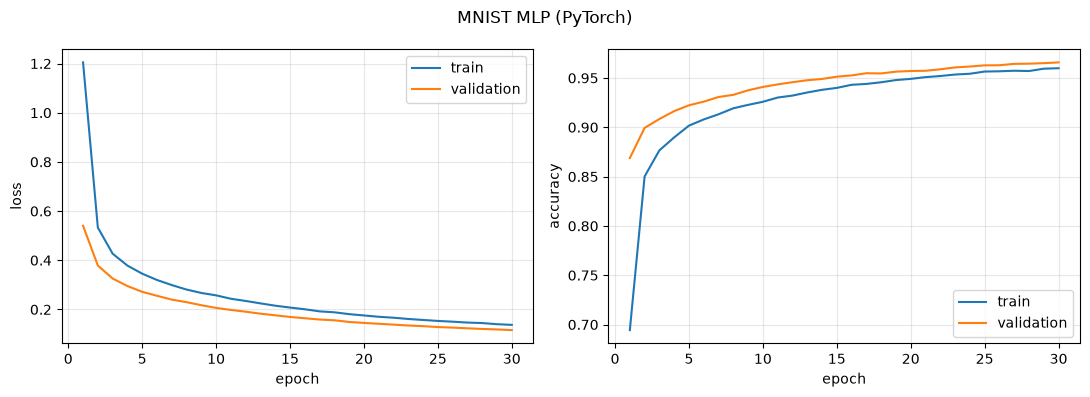

In [7]:
fig = plot_history(history, None if CHAY_THU else TEN, metric_name="accuracy",
                   title="MNIST MLP (PyTorch)")
plt.show()

# (4) Evaluate trained model

Keras gốc:
```python
score = model.evaluate(x_test, y_test)
print('Test loss:', score[0])
print('Test accuracy:', score[1])
```
Kết quả gốc: `Test loss: 0.1143`, `Test accuracy: 0.9648`.

In [8]:
score = evaluate(model, test_loader, loss_fn, accuracy)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.11594062259793282
Test accuracy: 0.9658


In [9]:
# Lưu kết quả và ghi một dòng vào results/so_sanh.csv (bỏ qua khi chạy thử)
if not CHAY_THU:
    save_history(history, TEN, metric_name="accuracy")
    save_metrics(TEN, test_loss=score[0], test_metric=score[1], n_params=n_params,
                 epochs_ran=len(history["loss"]), best_epoch=None, train_time_s=train_time,
                 device=device_name(device), seed=0)
    ghi_so_sanh(TEN, "1. MLP", "test_acc", keras=0.9648, pytorch=score[1],
                keras_params=669706, pytorch_params=n_params, epochs_keras=30, epochs_pytorch=epochs,
                optimizer="SGD", lr=lr, batch=batch_size, device=device_name(device),
                train_time_s=train_time, seed=0,
                ghi_chu="Keras gốc chạy trên TensorFlow 2.14, Colab T4; PyTorch khởi tạo glorot như Keras")

so_sanh.csv: MNIST_MLP | test_acc Keras 0.9648 | PyTorch 0.9658 | chênh 0.0010


## Dự đoán một ảnh test ngẫu nhiên

Keras gốc:
```python
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]
test_img = x_test[random_test_index]
test_label = np.argmax(y_test[random_test_index])
pred_label = model.predict(np.expand_dims(test_img, axis=0))
pred_label = np.argmax(pred_label)
```
`predict` trả logits; `argmax` của logits và của softmax là một, nên không cần softmax để lấy nhãn.

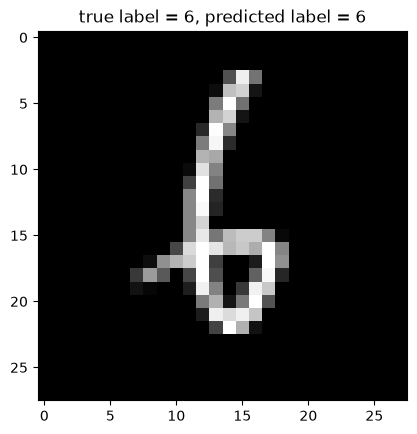

In [10]:
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]
test_img = x_test[random_test_index]
test_label = int(y_test[random_test_index])

pred_label = predict(model, test_img.unsqueeze(0))    # unsqueeze(0) = np.expand_dims(..., axis=0)
pred_label = int(pred_label.argmax(dim=1))

plt.imshow(test_img, cmap='gray')
plt.title('true label = %d, predicted label = %d' % (test_label, pred_label))
plt.show()

## Kiểm tra shape và đầu ra của `predict`

Gốc kiểm `model.input_shape, model.output_shape`, `np.sum(y_pred, axis=1)` (= 1 vì có softmax) và `np.argmax`. Mô hình PyTorch không lưu shape vào/ra, nên in shape của tensor thật.

In [11]:
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]
test_img = x_test[random_test_index]
test_label = int(y_test[random_test_index])
print("test_label:", test_label)
print("test_img.shape:", tuple(test_img.shape))
print("test_img.unsqueeze(0).shape:", tuple(test_img.unsqueeze(0).shape))   # (1, 28, 28)

test_label: 1
test_img.shape: (28, 28)
test_img.unsqueeze(0).shape: (1, 28, 28)


In [12]:
logits = predict(model, test_img.unsqueeze(0))
y_pred = torch.softmax(logits, dim=1)        # Keras: đầu ra đã là softmax; PyTorch: tự áp
print("y_pred.shape:", tuple(y_pred.shape))                 # (1, 10)
print("tổng xác suất:", y_pred.sum(dim=1))                  # = 1
print("argmax:", y_pred.argmax(dim=1))

y_pred.shape: (1, 10)
tổng xác suất: tensor([1.0000])
argmax: tensor([1])


## Lấy đặc trưng lớp `fc2`

Keras gốc:
```python
model1 = Model(inputs=model.input, outputs=[model.get_layer("fc2").output, model.output])
y_feat, y_pred = model1.predict(np.expand_dims(test_img, axis=0))
y_feat.shape, y_pred.shape     # ((1, 512), (1, 10))
```
PyTorch: gọi `forward(..., return_features=True)`. Đặc trưng lấy **sau relu** vì `Dense(..., activation='relu', name='fc2')` của Keras gộp cả relu, nên nhiều giá trị bằng 0 như output gốc.

In [13]:
model.eval()
with torch.no_grad():
    y_feat, y_logits = model(test_img.unsqueeze(0).to(device), return_features=True)
y_feat, y_pred = y_feat.cpu(), torch.softmax(y_logits, dim=1).cpu()
print(tuple(y_feat.shape), tuple(y_pred.shape))
print("số phần tử bằng 0 (do relu):", int((y_feat == 0).sum()), "/ 512")
y_feat[0, :20]

(1, 512) (1, 10)
số phần tử bằng 0 (do relu): 193 / 512


tensor([0.7243, 0.2223, 0.2972, 0.3775, 0.0000, 0.7428, 0.0000, 0.0221, 0.0000,
        0.3365, 0.0000, 0.0690, 0.0000, 0.9216, 0.0000, 0.0204, 0.2696, 0.0000,
        0.0000, 0.0000])